# Spam Email Detection with NLP
## Notebook 4 — Model Training and Comparison
**Author: Tinashe Clifford Makandise**

Compare a majority-class baseline, Multinomial Naive Bayes and Logistic Regression. Use the two TF-IDF candidates defined in Notebook 3 and the same five group-aware folds. Select by mean spam-class F1. The final test CSV is not opened.

Run Notebooks 1–3 first. Save here in `notebooks/`; run cells in order. Required libraries: pandas, numpy, scikit-learn, matplotlib and threadpoolctl (installed with scikit-learn). Runtime depends on your computer. No full emails are printed.

This is a small fixed candidate comparison, not an exhaustive hyperparameter search. Cross-validation scores used for selection are development results, not the final unbiased performance estimate.

In [1]:
from pathlib import Path
import json, hashlib, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, confusion_matrix)
from threadpoolctl import threadpool_limits
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
manifest = json.loads((REPORTS / "data_manifest.json").read_text(encoding="utf-8"))
plan = json.loads((REPORTS / "feature_engineering_plan.json").read_text(encoding="utf-8"))
train_path = ROOT / "data/processed/train.csv"
train_hash = hashlib.sha256(train_path.read_bytes()).hexdigest()
assert train_hash == manifest["train_file_sha256"] == plan["train_file_sha256"]
train = pd.read_csv(train_path, keep_default_na=False)
assert len(train) == manifest["train_rows"]
assert set(train.row_id) == set(manifest["train_row_ids"])
assert set(train.group_id) == set(manifest["train_groups"])
assert set(train.group_id).isdisjoint(manifest["test_groups"])
assert train.spam.isin([0, 1]).all() and train.text.str.strip().ne("").all()
X, y, groups = train.text, train.spam.to_numpy(), train.group_id
cv = StratifiedGroupKFold(**{k: v for k, v in plan["validation"].items() if k != "method"})
folds = list(cv.split(X, y, groups))
for fit_idx, valid_idx in folds:
    assert set(groups.iloc[fit_idx]).isdisjoint(groups.iloc[valid_idx])
assert sorted(np.concatenate([v for _, v in folds]).tolist()) == list(range(len(y)))
print(f"Verified {len(train):,} training rows and {len(folds)} disjoint-group folds. Test CSV unopened.")

Verified 4,547 training rows and 5 disjoint-group folds. Test CSV unopened.


### 1. Metrics and decision rule
Spam is class 1. Precision asks how many spam flags were correct; recall asks how many spam messages were caught. F1 balances these. A false positive is a legitimate email incorrectly flagged as spam; a false negative is missed spam. Average precision summarises ranking performance across thresholds.

Accuracy alone is misleading with an imbalanced dataset. We use each classifier's standard `predict` decision rule throughout; there is no threshold tuning here. Probability outputs are uncalibrated model estimates, not confidence guarantees. Each row has equal metric weight, so larger retained groups contribute more than smaller groups.

In [2]:
def evaluate(actual, predicted, spam_score):
    tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(actual, predicted),
            "precision": precision_score(actual, predicted, zero_division=0),
            "recall": recall_score(actual, predicted, zero_division=0),
            "f1": f1_score(actual, predicted, zero_division=0),
            "average_precision": average_precision_score(actual, spam_score),
            "false_positive_rate": fp / (fp + tn),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

results = []
oof = {}
def record(name, fold, valid_idx, predicted, score, seconds):
    results.append({"candidate": name, "fold": fold, "fit_seconds": seconds,
                    **evaluate(y[valid_idx], predicted, score)})
    if name not in oof:
        oof[name] = {"predicted": np.full(len(y), -1, dtype=int),
                     "score": np.full(len(y), np.nan)}
    oof[name]["predicted"][valid_idx] = predicted
    oof[name]["score"][valid_idx] = score

### 2. Majority-class baseline
This baseline always predicts the most frequent class in the fitting fold. It uses no email features. It should have reasonable accuracy but zero spam recall and F1 when ham is the majority. Its average precision reflects a constant-score ranking baseline.

In [3]:
for fold, (fit_idx, valid_idx) in enumerate(folds, 1):
    baseline = DummyClassifier(strategy="most_frequent")
    start = time.perf_counter()
    baseline.fit(np.zeros((len(fit_idx), 1)), y[fit_idx])
    seconds = time.perf_counter() - start
    dummy_valid = np.zeros((len(valid_idx), 1))
    predicted = baseline.predict(dummy_valid)
    score = baseline.predict_proba(dummy_valid)[:, list(baseline.classes_).index(1)]
    record("majority_baseline", fold, valid_idx, predicted, score, seconds)
print("Baseline completed on all five folds.")

Baseline completed on all five folds.


### 3. Fit TF-IDF within each fold and train classifiers
For each representation and fold, fit a fresh vectorizer on fitting rows only. Transform validation rows using that vocabulary. Both classifiers reuse these identical fold-specific features, which avoids repeating expensive tokenization without leaking validation statistics. This is equivalent to fitting the TF-IDF stage separately inside each candidate pipeline.

We retain Notebook 3's fixed settings: Naive Bayes alpha=1 and Logistic Regression C=1, max_iter=2000. Stopword choices are compared, not assumed beneficial. We do not add Random Forest at this stage; sparse linear and probabilistic baselines provide a manageable first experiment. No candidate is fitted on the test data.

In [4]:
settings = dict(plan["vectorizer_settings"])
settings["ngram_range"] = tuple(settings["ngram_range"])
for representation, stop_words in plan["candidates"].items():
    for fold, (fit_idx, valid_idx) in enumerate(folds, 1):
        vectorizer = TfidfVectorizer(**settings, stop_words=stop_words)
        start = time.perf_counter()
        fit_features = vectorizer.fit_transform(X.iloc[fit_idx])
        valid_features = vectorizer.transform(X.iloc[valid_idx])
        vector_seconds = time.perf_counter() - start
        for model_name, estimator in [
            ("naive_bayes", MultinomialNB(alpha=1.0)),
            ("logistic_regression", LogisticRegression(C=1.0, max_iter=2000, random_state=42))
        ]:
            start = time.perf_counter()
            with threadpool_limits(limits=1):
                estimator.fit(fit_features, y[fit_idx])
            fit_seconds = time.perf_counter() - start + vector_seconds
            if model_name == "logistic_regression":
                assert estimator.n_iter_.max() < estimator.max_iter, "Increase max_iter and rerun."
            predicted = estimator.predict(valid_features)
            score = estimator.predict_proba(valid_features)[:, list(estimator.classes_).index(1)]
            record(f"{model_name}__{representation}", fold, valid_idx, predicted, score, fit_seconds)
        print(f"Completed {representation}: fold {fold}/{len(folds)}")
        del fit_features, valid_features, vectorizer
print("All candidates evaluated; TF-IDF fitted separately in every fold.")

Completed word_tfidf: fold 1/5
Completed word_tfidf: fold 2/5
Completed word_tfidf: fold 3/5
Completed word_tfidf: fold 4/5
Completed word_tfidf: fold 5/5
Completed word_tfidf_stopwords: fold 1/5
Completed word_tfidf_stopwords: fold 2/5
Completed word_tfidf_stopwords: fold 3/5
Completed word_tfidf_stopwords: fold 4/5
Completed word_tfidf_stopwords: fold 5/5
All candidates evaluated; TF-IDF fitted separately in every fold.


### 4. Compare cross-validation results
Means and standard deviations below describe variation across the five folds. Standard deviations are not confidence intervals. Each candidate uses the same folds, making comparisons more meaningful. Fit time includes feature extraction and classifier fitting; it is not a production latency benchmark.

Select the highest mean F1 among learned models. An exact tie is broken by candidate name for reproducibility. Small score differences should not be interpreted as statistical proof of superiority.

In [5]:
fold_results = pd.DataFrame(results)
metrics = ["accuracy", "precision", "recall", "f1", "average_precision", "false_positive_rate", "fit_seconds"]
summary = fold_results.groupby("candidate")[metrics].agg(["mean", "std"])
summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
summary = summary.reset_index().sort_values(["f1_mean", "candidate"], ascending=[False, True])
print(summary[["candidate", "f1_mean", "f1_std", "precision_mean", "recall_mean", "average_precision_mean", "accuracy_mean"]].round(4).to_string(index=False))
learned = summary[summary.candidate != "majority_baseline"]
winner = learned.iloc[0]
selected_name = winner["candidate"]
print("Selected candidate:", selected_name)
print(f"Selection CV spam F1: {winner['f1_mean']:.4f} ± {winner['f1_std']:.4f} (fold SD)")
assert len(fold_results) == 25
for outputs in oof.values():
    assert (outputs["predicted"] >= 0).all() and np.isfinite(outputs["score"]).all()

                                candidate  f1_mean  f1_std  precision_mean  recall_mean  average_precision_mean  accuracy_mean
logistic_regression__word_tfidf_stopwords   0.9567  0.0083          0.9970       0.9196                  0.9980         0.9800
          logistic_regression__word_tfidf   0.9478  0.0057          0.9960       0.9040                  0.9979         0.9760
        naive_bayes__word_tfidf_stopwords   0.8932  0.0099          1.0000       0.8071                  0.9977         0.9536
                  naive_bayes__word_tfidf   0.8691  0.0224          0.9988       0.7697                  0.9968         0.9444
                        majority_baseline   0.0000  0.0000          0.0000       0.0000                  0.2406         0.7594
Selected candidate: logistic_regression__word_tfidf_stopwords
Selection CV spam F1: 0.9567 ± 0.0083 (fold SD)


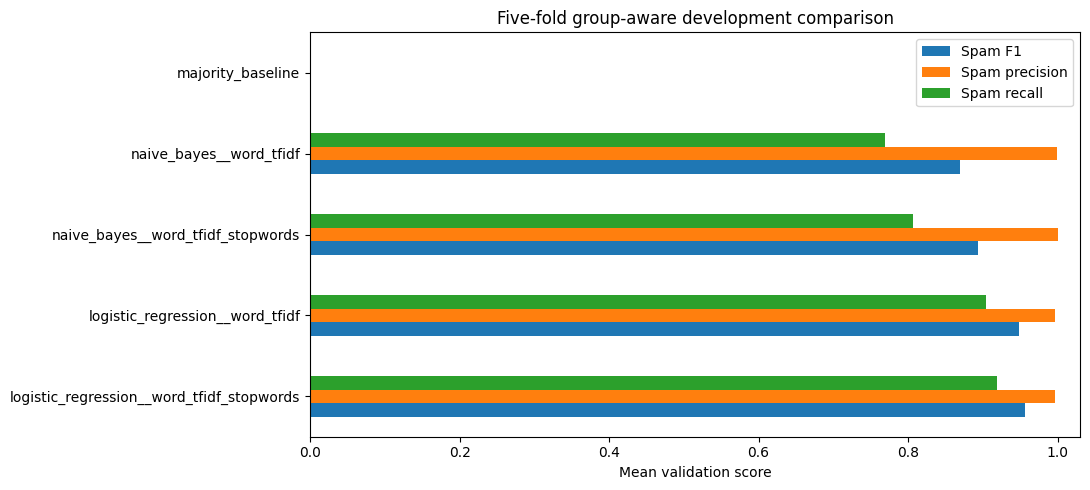

In [6]:
plot_data = summary.set_index("candidate")
ax = plot_data[["f1_mean", "precision_mean", "recall_mean"]].plot.barh(figsize=(11, 5))
ax.set(xlabel="Mean validation score", ylabel="", xlim=(0, 1.03), title="Five-fold group-aware development comparison")
ax.legend(["Spam F1", "Spam precision", "Spam recall"], loc="upper right")
plt.tight_layout()
plt.savefig(FIGURES / "04_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 5. Examine selected candidate's out-of-fold errors
Each prediction below was made by a model that did not fit that row or its normalised group. Pooled out-of-fold metrics can differ from mean fold metrics. Since these same folds selected the candidate, they remain development diagnostics with selection optimism. The untouched test set will provide final evaluation.

We report aggregate counts without printing message contents. A false-positive rate describes errors among legitimate emails; it differs from one minus spam precision.

{
  "accuracy": 0.9799868044864746,
  "precision": 0.9970267591674926,
  "recall": 0.9195612431444241,
  "f1": 0.9567284831193533,
  "average_precision": 0.99802532549667,
  "false_positive_rate": 0.0008688097306689834,
  "tn": 3450,
  "fp": 3,
  "fn": 88,
  "tp": 1006
}


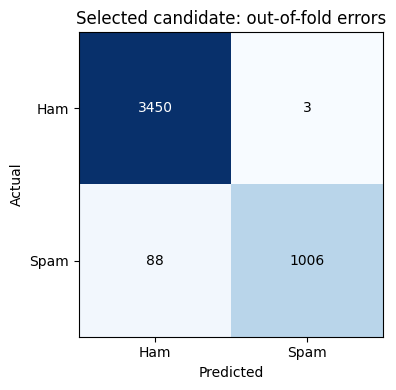

In [7]:
selected_oof = oof[selected_name]
pooled = evaluate(y, selected_oof["predicted"], selected_oof["score"])
print(json.dumps(pooled, indent=2))
cm = confusion_matrix(y, selected_oof["predicted"], labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha="center", va="center", color="white" if value > cm.max()/2 else "black")
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"],
       xlabel="Predicted", ylabel="Actual", title="Selected candidate: out-of-fold errors")
plt.tight_layout()
plt.savefig(FIGURES / "04_oof_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### 6. Freeze the selection for final evaluation
Save the chosen model and representation settings, all fold metrics, and aggregate summaries. No production model is exported yet. Notebook 5 will reconstruct the selected pipeline, fit it on all training rows, evaluate once on the reserved test partition and export it for Streamlit.

Keep the standard classifier decision rule unchanged for that evaluation. Changing preprocessing or choosing another model after inspecting the final test results would require a new independent evaluation set. Historical source vocabulary, possible near-duplicates and a random group split limit generalisation to modern inboxes.

In [8]:
model_name, representation = selected_name.split("__", 1)
selection = {
    "author": "Tinashe Clifford Makandise", "selected_candidate": selected_name,
    "model_name": model_name, "representation": representation,
    "vectorizer_settings": settings, "stop_words": plan["candidates"][representation],
    "classifier_settings": ({"alpha": 1.0} if model_name == "naive_bayes" else {"C": 1.0, "max_iter": 2000, "random_state": 42}),
    "selection_metric": "mean five-fold spam-class F1", "cv_f1_mean": float(winner["f1_mean"]),
    "cv_f1_std": float(winner["f1_std"]), "pooled_development_metrics": pooled,
    "decision_rule": "classifier.predict default; no threshold tuning",
    "train_file_sha256": train_hash,
    "feature_plan_sha256": hashlib.sha256((REPORTS / "feature_engineering_plan.json").read_bytes()).hexdigest(),
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
    "test_evaluated": False,
}
fold_results.to_csv(REPORTS / "model_cv_fold_results.csv", index=False)
summary.to_csv(REPORTS / "model_cv_comparison.csv", index=False)
(REPORTS / "selected_model.json").write_text(json.dumps(selection, indent=2), encoding="utf-8")
assert hashlib.sha256(train_path.read_bytes()).hexdigest() == train_hash
print("Selection and development metrics saved. Test CSV not opened; training CSV unchanged.")
print("Next: Notebook 5 — Final Evaluation and Model Export.")

Selection and development metrics saved. Test CSV not opened; training CSV unchanged.
Next: Notebook 5 — Final Evaluation and Model Export.


### Review questions
1. Why does the majority baseline's accuracy hide its failure to catch spam?
2. What is the practical cost of a false positive?
3. Why do we refit TF-IDF in every fold?
4. Why are the selected model's CV results still development estimates?
5. What new evidence would we need before claiming this model generalises to current email traffic?